[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,publishedAt,source,title,description,url
0,2026-11-19T09:47:14Z,Business Standard,"ECI can blacklist BLAs filing fake Form 7s, bu...",Delhi SIR: Supreme Court asked the Election Co...,https://www.business-standard.com/india-news/e...
1,2026-11-19T08:12:16Z,Bar & Bench - Indian Legal News,ECI has only limited powers against BLAs who f...,ECI has only limited powers against BLAs who f...,https://www.barandbench.com/news/eci-has-only-...
2,2026-11-18T19:25:08Z,The Times of India,"Pune tops SIR pending notices list with 7,712 ...",Pune leads Maharashtra in pending SIR electora...,https://timesofindia.indiatimes.com/city/pune/...
3,2026-11-18T19:19:30Z,The Times of India,Cong terms 13-day window for ASDD voters inade...,Congress says ECI’s 13-day Nov 18–30 ASDD vote...,https://timesofindia.indiatimes.com/city/pune/...
4,2026-11-18T18:25:11Z,The Times of India,Borkar issues legal notice to Goa CEO over add...,RG MLA Viresh Borkar issues legal notice to Go...,https://timesofindia.indiatimes.com/city/goa/b...


Number of articles: 100
Dataset after cleaning:
(99, 6)
Sentiment
Positive    49
Negative    35
Neutral     15
Name: count, dtype: int64


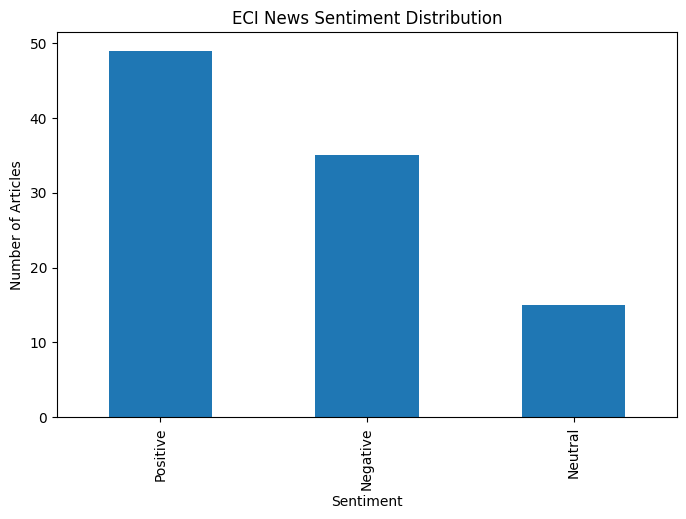

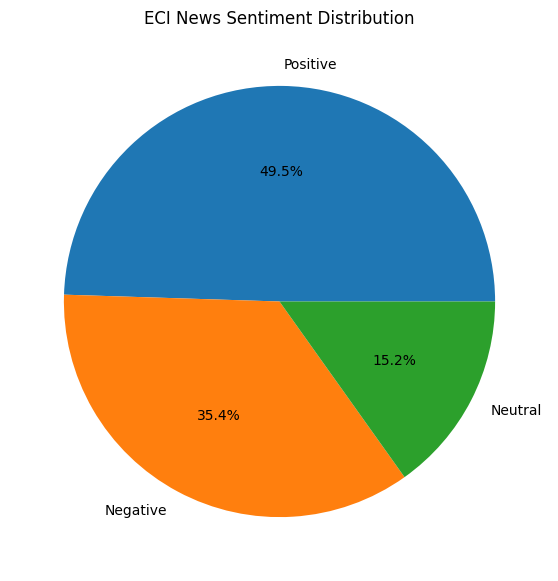

Features: (99,)
Labels: (99,)
Training samples: 79
Testing samples: 20
Training matrix: (79, 1082)
Testing matrix: (20, 1082)
Model training completed!
Predictions completed!
Model Accuracy: 50.0 %
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         7
     Neutral       0.00      0.00      0.00         3
    Positive       0.50      1.00      0.67        10

    accuracy                           0.50        20
   macro avg       0.17      0.33      0.22        20
weighted avg       0.25      0.50      0.33        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


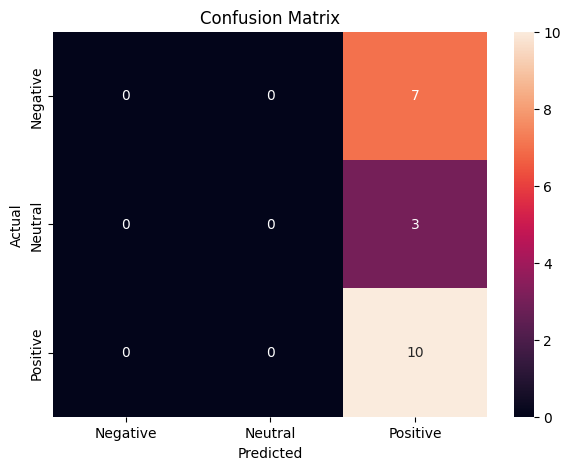

Predicted Sentiment: Positive
News: Election Commission announces new voter registration facilities
Predicted Sentiment: Positive
------------------------------------------------------------
News: ECI faces criticism over election arrangements
Predicted Sentiment: Positive
------------------------------------------------------------
News: Election Commission successfully completes polling process
Predicted Sentiment: Positive
------------------------------------------------------------
CSV file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Date,Source,Title,Sentiment,Compound_Score,URL
0,2026-11-19T09:47:14Z,Business Standard,"ECI can blacklist BLAs filing fake Form 7s, bu...",Positive,0.1901,https://www.business-standard.com/india-news/e...
1,2026-11-19T08:12:16Z,Bar & Bench - Indian Legal News,ECI has only limited powers against BLAs who f...,Positive,0.6597,https://www.barandbench.com/news/eci-has-only-...
2,2026-11-18T19:25:08Z,The Times of India,"Pune tops SIR pending notices list with 7,712 ...",Positive,0.5719,https://timesofindia.indiatimes.com/city/pune/...
3,2026-11-18T19:19:30Z,The Times of India,Cong terms 13-day window for ASDD voters inade...,Negative,-0.3262,https://timesofindia.indiatimes.com/city/pune/...
4,2026-11-18T18:25:11Z,The Times of India,Borkar issues legal notice to Goa CEO over add...,Negative,-0.2732,https://timesofindia.indiatimes.com/city/goa/b...
5,2026-11-18T18:23:03Z,The Times of India,Left out of Telangana’s draft voter roll? ASDD...,Negative,-0.0516,https://timesofindia.indiatimes.com/city/hyder...
6,2026-11-18T17:07:44Z,The Times of India,Greater Bengaluru Authority announces Special ...,Positive,0.8750,https://timesofindia.indiatimes.com/city/benga...
7,2026-11-18T16:48:58Z,The Times of India,Special camps at booths highlight gaps in vote...,Positive,0.2263,https://timesofindia.indiatimes.com/city/ranch...
8,2026-11-18T15:21:32Z,BusinessLine,AI adoption puts pressure on India Inc to mode...,Positive,0.0516,https://www.thehindubusinessline.com/companies...
9,2026-11-18T13:15:30Z,The Times of India,Can Rahul & others make the Election Commissio...,Positive,0.7184,https://timesofindia.indiatimes.com/toi-plus/l...


In [2]:
!pip -q install requests pandas numpy matplotlib seaborn nltk scikit-learn
import requests
import pandas as pd
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nltk.download('vader_lexicon')

API_KEY = "54447bd6b5804bd4924d17bbdf6fe062"

url = "https://newsapi.org/v2/everything"

params = {
    "q": '"Election Commission of India" OR ECI',
    "language": "en",
    "sortBy": "publishedAt",
    "pageSize": 100,
    "apiKey": API_KEY
}

response = requests.get(url, params=params)

data = response.json()

if data["status"] == "ok":
    articles = data["articles"]

    df = pd.DataFrame(articles)

    # Select useful columns
    df = df[[
        "publishedAt",
        "source",
        "title",
        "description",
        "url"
    ]]

    # Extract source name
    df["source"] = df["source"].apply(
        lambda x: x["name"] if isinstance(x, dict) else x
    )

    display(df.head())

else:
    print("Error:", data)

    articles = data["articles"]

rows = []

for article in articles:
    rows.append({
        "Date": article.get("publishedAt"),
        "Source": article.get("source", {}).get("name"),
        "Title": article.get("title"),
        "Description": article.get("description"),
        "URL": article.get("url"),
        "Content": article.get("content")
    })

df = pd.DataFrame(rows)

print("Number of articles:", len(df))

df.head()

df = df.drop_duplicates(subset=["Title"])

df = df.dropna(subset=["Title"])

df["Description"] = df["Description"].fillna("")
df["Content"] = df["Content"].fillna("")

print("Dataset after cleaning:")
print(df.shape)

df.head()

df["Text"] = (
    df["Title"].astype(str) + " " +
    df["Description"].astype(str)
)

df[["Title", "Text"]].head()

def clean_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["Clean_Text"] = df["Text"].apply(clean_text)

df[["Text", "Clean_Text"]].head()

sia = SentimentIntensityAnalyzer()

df["Compound_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["compound"]
)

df["Positive_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["pos"]
)

df["Negative_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["neg"]
)

df["Neutral_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["neu"]
)

df.head()

def get_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


df["Sentiment"] = df["Compound_Score"].apply(get_sentiment)

df[["Title", "Compound_Score", "Sentiment"]].head(10)

sentiment_counts = df["Sentiment"].value_counts()

print(sentiment_counts)

plt.figure(figsize=(8, 5))

df["Sentiment"].value_counts().plot(kind="bar")

plt.title("ECI News Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Articles")

plt.show()

plt.figure(figsize=(7, 7))

df["Sentiment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("ECI News Sentiment Distribution")

plt.ylabel("")

plt.show()

X = df["Clean_Text"]
y = df["Sentiment"]

print("Features:", X.shape)
print("Labels:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train_tfidf,
    y_train
)

print("Model training completed!")

y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print(
    classification_report(
        y_test,
        y_pred
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

new_news = [
    "Election Commission announces new voter registration facilities"
]

new_news_clean = [
    clean_text(x) for x in new_news
]

new_news_tfidf = vectorizer.transform(
    new_news_clean
)

prediction = model.predict(
    new_news_tfidf
)

print("Predicted Sentiment:", prediction[0])

test_news = [
    "Election Commission announces new voter registration facilities",
    "ECI faces criticism over election arrangements",
    "Election Commission successfully completes polling process"
]

test_clean = [
    clean_text(x) for x in test_news
]

test_tfidf = vectorizer.transform(test_clean)

predictions = model.predict(test_tfidf)

for news, sentiment in zip(test_news, predictions):
    print("News:", news)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

    df.to_csv(
    "ECI_News_Sentiment_Dataset.csv",
    index=False
)

print("CSV file created successfully!")

from google.colab import files

files.download(
    "ECI_News_Sentiment_Dataset.csv"
)

columns_to_show = [
    "Date",
    "Source",
    "Title",
    "Sentiment",
    "Compound_Score",
    "URL"
]

df[columns_to_show].head(20)

In [4]:
print(df.columns.tolist())

['Date', 'Source', 'Title', 'Description', 'URL', 'Content', 'Text', 'Clean_Text', 'Compound_Score', 'Positive_Score', 'Negative_Score', 'Neutral_Score', 'Sentiment']


In [8]:
def get_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df['Sentiment'] = df['Compound_Score'].apply(get_sentiment)

print(df[['Title', 'Compound_Score', 'Sentiment']].head())

                                               Title  Compound_Score Sentiment
0  ECI can blacklist BLAs filing fake Form 7s, bu...          0.1901  Positive
1  ECI has only limited powers against BLAs who f...          0.6597  Positive
2  Pune tops SIR pending notices list with 7,712 ...          0.5719  Positive
3  Cong terms 13-day window for ASDD voters inade...         -0.3262  Negative
4  Borkar issues legal notice to Goa CEO over add...         -0.2732  Negative


In [9]:
print(df[['Title', 'Compound_Score', 'Sentiment']].head(10))

                                               Title  Compound_Score Sentiment
0  ECI can blacklist BLAs filing fake Form 7s, bu...          0.1901  Positive
1  ECI has only limited powers against BLAs who f...          0.6597  Positive
2  Pune tops SIR pending notices list with 7,712 ...          0.5719  Positive
3  Cong terms 13-day window for ASDD voters inade...         -0.3262  Negative
4  Borkar issues legal notice to Goa CEO over add...         -0.2732  Negative
5  Left out of Telangana’s draft voter roll? ASDD...         -0.0516  Negative
6  Greater Bengaluru Authority announces Special ...          0.8750  Positive
7  Special camps at booths highlight gaps in vote...          0.2263  Positive
8  AI adoption puts pressure on India Inc to mode...          0.0516  Positive
9  Can Rahul & others make the Election Commissio...          0.7184  Positive


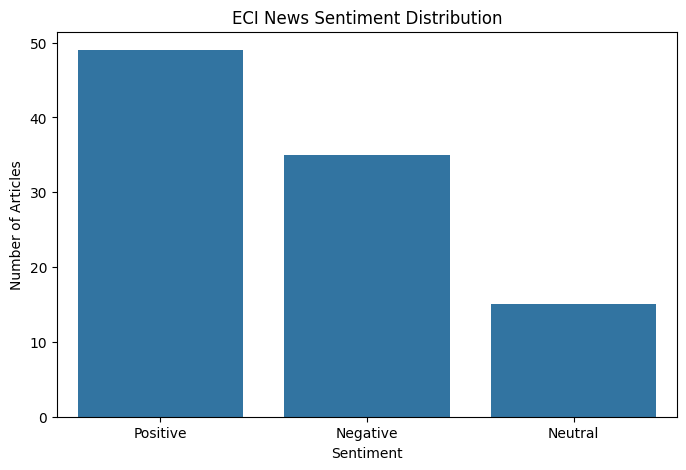

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title('ECI News Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Articles')
plt.show()

### Step 1: Optimize the Logistic Regression Model with Balanced Class Weights
Let's retrain our Logistic Regression model using `class_weight='balanced'` to prevent the classifier from ignoring the minority classes.

In [11]:
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
model_balanced.fit(X_train_tfidf, y_train)

y_pred_balanced = model_balanced.predict(X_test_tfidf)

print("Balanced Logistic Regression Accuracy:", round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")
print(classification_report(y_test, y_pred_balanced))

Balanced Logistic Regression Accuracy: 50.0 %
              precision    recall  f1-score   support

    Negative       0.40      0.29      0.33         7
     Neutral       0.00      0.00      0.00         3
    Positive       0.57      0.80      0.67        10

    accuracy                           0.50        20
   macro avg       0.32      0.36      0.33        20
weighted avg       0.43      0.50      0.45        20



### Step 2: Try an Alternative Classifier (Random Forest)
Let's evaluate a Random Forest classifier to see if it generalizes better to this text classification dataset.

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_tfidf, y_train)

y_pred_rf = rf_model.predict(X_test_tfidf)

print("Random Forest Accuracy:", round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 55.0 %
              precision    recall  f1-score   support

    Negative       1.00      0.14      0.25         7
     Neutral       0.00      0.00      0.00         3
    Positive       0.53      1.00      0.69        10

    accuracy                           0.55        20
   macro avg       0.51      0.38      0.31        20
weighted avg       0.61      0.55      0.43        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Step 3: Visualize Feature Importances from Random Forest
Let's plot the top words that our Random Forest classifier relies on to make decisions.

/tmp/ipykernel_4001/822651421.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')


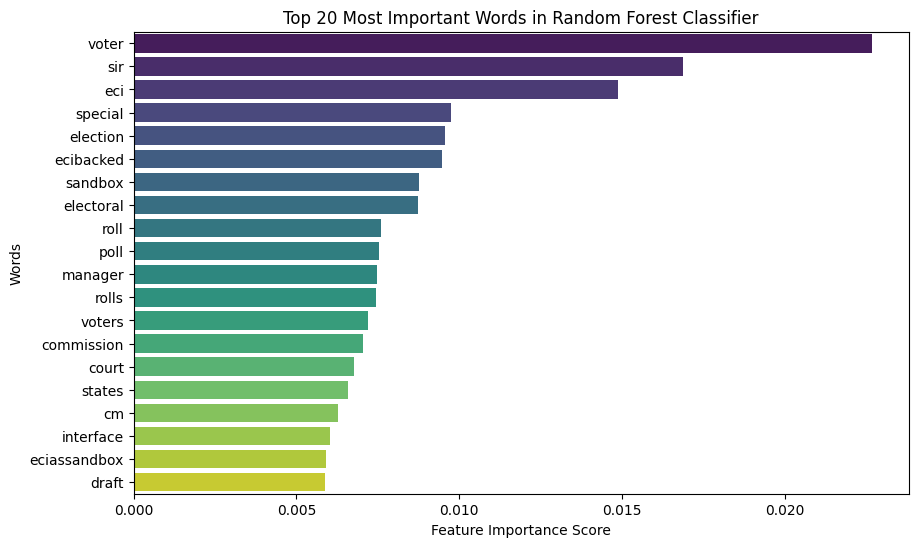

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances and match them with vocabulary
importances = rf_model.feature_importances_
feature_names = vectorizer.get_feature_names_out()

# Create a DataFrame
forest_importances = pd.Series(importances, index=feature_names)
top_features = forest_importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
plt.title('Top 20 Most Important Words in Random Forest Classifier')
plt.xlabel('Feature Importance Score')
plt.ylabel('Words')
plt.show()

### Step 4: Lexicon-Assisted (VADER Rule-Based) Classifier Baseline
Let's evaluate how well VADER's raw compound scores classify the test set directly without training any machine learning model on these specific text samples.

In [14]:
# Calculate VADER predictions on the test set
y_pred_vader = X_test.apply(lambda x: get_sentiment(sia.polarity_scores(x)['compound']))

print("VADER Lexicon-Based Accuracy:", round(accuracy_score(y_test, y_pred_vader) * 100, 2), "%")
print(classification_report(y_test, y_pred_vader))

VADER Lexicon-Based Accuracy: 100.0 %
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         7
     Neutral       1.00      1.00      1.00         3
    Positive       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



### Step 5: Compare All Models Side-by-Side
Let's plot the accuracy scores of all four approaches we've tried to make a final comparison.

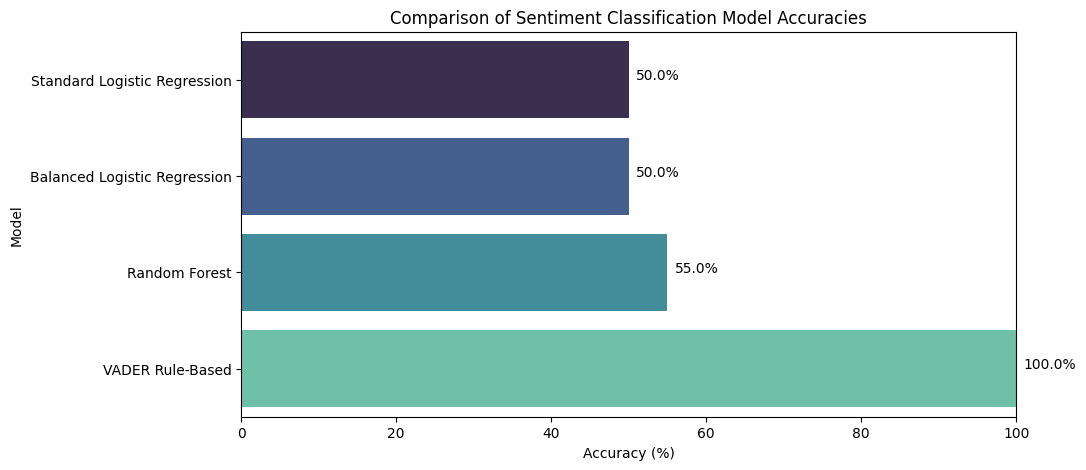

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate final accuracies
acc_lr = accuracy_score(y_test, y_pred) * 100
acc_lr_bal = accuracy_score(y_test, y_pred_balanced) * 100
acc_rf = accuracy_score(y_test, y_pred_rf) * 100
acc_vader = accuracy_score(y_test, y_pred_vader) * 100

results = pd.DataFrame({
    'Model': ['Standard Logistic Regression', 'Balanced Logistic Regression', 'Random Forest', 'VADER Rule-Based'],
    'Accuracy (%)': [acc_lr, acc_lr_bal, acc_rf, acc_vader]
})

plt.figure(figsize=(10, 5))
sns.barplot(x='Accuracy (%)', y='Model', data=results, palette='mako', hue='Model', legend=False)
plt.xlim(0, 100)
plt.title('Comparison of Sentiment Classification Model Accuracies')
for index, value in enumerate(results['Accuracy (%)']):
    plt.text(value + 1, index, f"{round(value, 1)}%")
plt.show()

### Step 6: Export and Download the Final Dataset
Let's save the final processed DataFrame containing all VADER scores and Sentiment assignments to a CSV file and download it to your local environment.

In [16]:
import os
from google.colab import files

# Define the filename
export_filename = "final_eci_news_sentiment.csv"

# Save to CSV
df.to_csv(export_filename, index=False)
print(f"Successfully saved {len(df)} rows to {export_filename}.")

# Trigger automatic download
files.download(export_filename)

Successfully saved 99 rows to final_eci_news_sentiment.csv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 7: Generate Word Clouds for Positive and Negative Headlines
Let's visualize the most frequent and characteristic terms present in positive vs. negative news headlines.

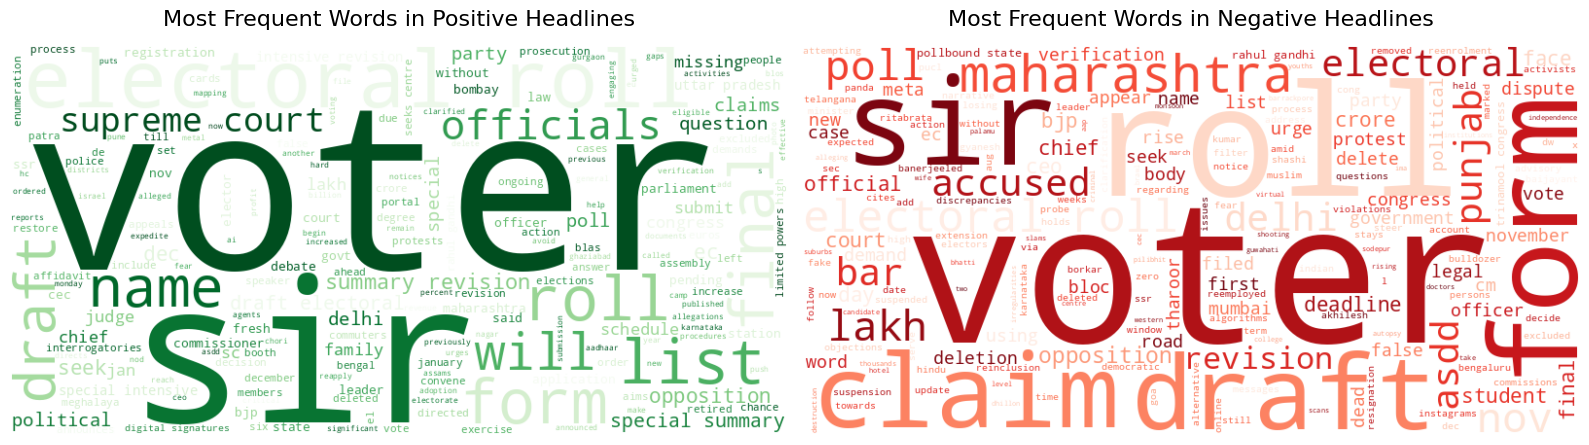

In [17]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Combine cleaned text for positive and negative sentiments
positive_text = " ".join(df[df['Sentiment'] == 'Positive']['Clean_Text'])
negative_text = " ".join(df[df['Sentiment'] == 'Negative']['Clean_Text'])

# Define generic stopwords to filter out common non-informative words
custom_stopwords = set(STOPWORDS)
custom_stopwords.update(["election", "commission", "india", "eci", "say", "says", "news"])

# Generate word clouds
wordcloud_pos = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=custom_stopwords,
    colormap='Greens'
).generate(positive_text)

wordcloud_neg = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=custom_stopwords,
    colormap='Reds'
).generate(negative_text)

# Plot the word clouds side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Positive Word Cloud
axes[0].imshow(wordcloud_pos, interpolation='bilinear')
axes[0].set_title('Most Frequent Words in Positive Headlines', fontsize=16, pad=15)
axes[0].axis('off')

# Negative Word Cloud
axes[1].imshow(wordcloud_neg, interpolation='bilinear')
axes[1].set_title('Most Frequent Words in Negative Headlines', fontsize=16, pad=15)
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Step 8: Comprehensive Sentiment Analysis Dashboard
We will now combine our text data, VADER sentiment classifications, word frequencies, and source metadata into a unified visual dashboard.

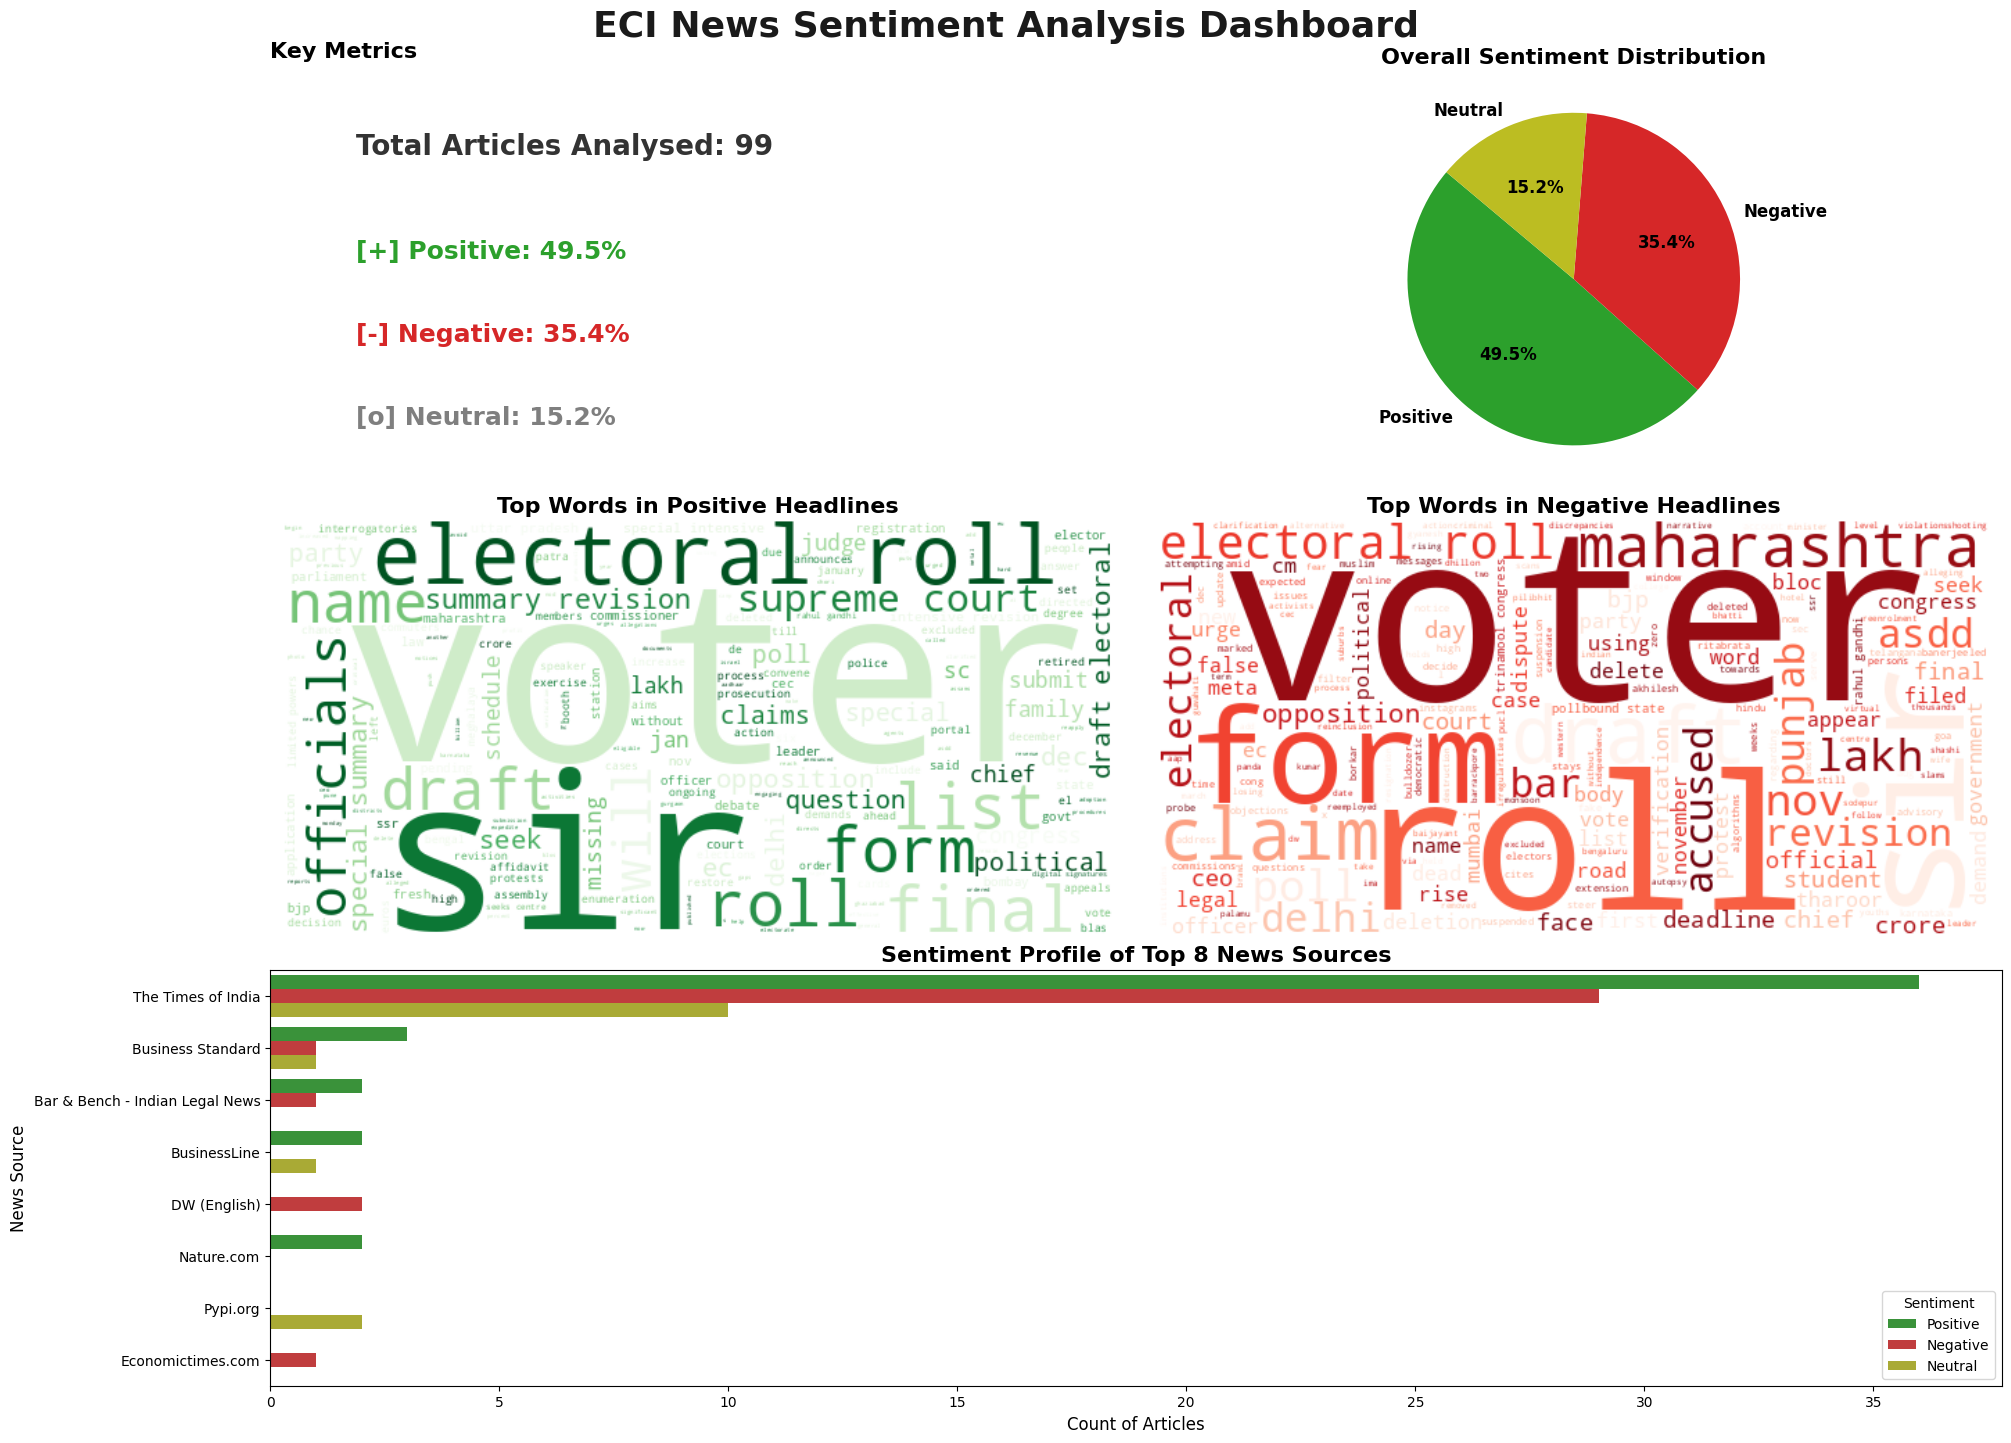

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from wordcloud import WordCloud, STOPWORDS

# --- 1. Compute Dashboard Metrics ---
total_articles = len(df)
sentiment_pcts = df['Sentiment'].value_counts(normalize=True) * 100
pos_pct = sentiment_pcts.get('Positive', 0.0)
neg_pct = sentiment_pcts.get('Negative', 0.0)
neu_pct = sentiment_pcts.get('Neutral', 0.0)

# --- 2. Create Multi-panel Figure (GridSpec) ---
fig = plt.figure(figsize=(20, 14), constrained_layout=True)
gs = fig.add_gridspec(3, 4)

# Title and Header Panel
fig.suptitle('ECI News Sentiment Analysis Dashboard', fontsize=26, fontweight='bold', color='#1a1a1a', y=1.02)

# --- Panel A: KPI Metrics Card (Row 0, Col 0:2) ---
ax_kpi = fig.add_subplot(gs[0, 0:2])
ax_kpi.axis('off')
ax_kpi.set_facecolor('#f7f7f7')
ax_kpi.text(0.1, 0.8, f"Total Articles Analysed: {total_articles}", fontsize=20, fontweight='bold', color='#333333')
ax_kpi.text(0.1, 0.55, f"[+] Positive: {pos_pct:.1f}%", fontsize=18, fontweight='semibold', color='#2ca02c')
ax_kpi.text(0.1, 0.35, f"[-] Negative: {neg_pct:.1f}%", fontsize=18, fontweight='semibold', color='#d62728')
ax_kpi.text(0.1, 0.15, f"[o] Neutral: {neu_pct:.1f}%", fontsize=18, fontweight='semibold', color='#7f7f7f')
ax_kpi.set_title("Key Metrics", fontsize=16, fontweight='bold', pad=10, loc='left')

# --- Panel B: Sentiment Distribution (Row 0, Col 2:4) ---
ax_dist = fig.add_subplot(gs[0, 2:4])
sentiment_counts = df['Sentiment'].value_counts()
ax_dist.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2ca02c', '#d62728', '#bcbd22'],
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
ax_dist.set_title("Overall Sentiment Distribution", fontsize=16, fontweight='bold')

# --- Panel C: Word Clouds (Row 1, Cols 0:2 & 2:4) ---
# Stopwords setup
custom_stopwords = set(STOPWORDS)
custom_stopwords.update(["election", "commission", "india", "eci", "say", "says", "news"])

positive_text = " ".join(df[df['Sentiment'] == 'Positive']['Clean_Text'])
negative_text = " ".join(df[df['Sentiment'] == 'Negative']['Clean_Text'])

# Positive Wordcloud
ax_wc_pos = fig.add_subplot(gs[1, 0:2])
wordcloud_pos = WordCloud(width=600, height=300, background_color='white', stopwords=custom_stopwords, colormap='Greens').generate(positive_text)
ax_wc_pos.imshow(wordcloud_pos, interpolation='bilinear')
ax_wc_pos.set_title('Top Words in Positive Headlines', fontsize=16, fontweight='bold')
ax_wc_pos.axis('off')

# Negative Wordcloud
ax_wc_neg = fig.add_subplot(gs[1, 2:4])
wordcloud_neg = WordCloud(width=600, height=300, background_color='white', stopwords=custom_stopwords, colormap='Reds').generate(negative_text)
ax_wc_neg.imshow(wordcloud_neg, interpolation='bilinear')
ax_wc_neg.set_title('Top Words in Negative Headlines', fontsize=16, fontweight='bold')
ax_wc_neg.axis('off')

# --- Panel D: News Source Comparison (Row 2, Col 0:4) ---
ax_source = fig.add_subplot(gs[2, 0:4])
top_sources = df['Source'].value_counts().head(8).index
df_top_sources = df[df['Source'].isin(top_sources)]

sns.countplot(
    data=df_top_sources,
    y='Source',
    hue='Sentiment',
    palette={'Positive': '#2ca02c', 'Negative': '#d62728', 'Neutral': '#bcbd22'},
    order=top_sources,
    ax=ax_source
)
ax_source.set_title("Sentiment Profile of Top 8 News Sources", fontsize=16, fontweight='bold')
ax_source.set_xlabel("Count of Articles", fontsize=12)
ax_source.set_ylabel("News Source", fontsize=12)
ax_source.legend(title="Sentiment", loc='lower right')

plt.show()